In [1]:
import sys
import os
from pathlib import Path

if 'google.colab' in sys.modules:
    print("Ambiente Colab rilevato. Inizializzazione in corso...")
    
    # 1. Monta Drive (se non già montato)
    from google.colab import drive
    if not os.path.exists('/content/drive'):
        drive.mount('/content/drive')
        
    # Imposta la root del Drive su Colab
    BASE_DIR = Path('/content/drive/Shareddrives/Progetti/Progetto_MLDM')

    GIT_BRANCH = 'zone-test'
    
    # 2. Clona/Aggiorna la repo
    REPO_DIR = '/content/crop-spatial-classification'
    if not os.path.exists(REPO_DIR):
        !git clone -b {GIT_BRANCH} https://github.com/SimoRinaldi/crop-spatial-classification.git {REPO_DIR}
    else:
        !cd {REPO_DIR} && git fetch origin && git checkout -B {GIT_BRANCH} origin/{GIT_BRANCH} && git reset --hard origin/{GIT_BRANCH} && git clean -fd
    
    # 3. Aggancia la cartella per permettere gli import
    if REPO_DIR not in sys.path:
        sys.path.append(REPO_DIR)
        
    # 4. Installa i requisiti in modo silenzioso
    %pip install -q -r {REPO_DIR}/requirements.txt
    print("Setup ambiente Colab completato! Branch attivo su Colab: ", GIT_BRANCH)
    
else:
    print("Ambiente Locale rilevato. Procedo con l'esecuzione...")
    
    BASE_DIR = Path.cwd().parent

    if str(BASE_DIR) not in sys.path:
        sys.path.append(str(BASE_DIR))

# =============================
# DEFINIZIONE PATH UNIVERSALI
# =============================
DATA_DIR = BASE_DIR / 'data'
RAW_DIR = DATA_DIR / 'raw'
INTERIM_DIR = DATA_DIR / 'interim'
PROCESSED_DIR = DATA_DIR / 'processed'
MODELS_DIR = DATA_DIR / 'models'

# Test di verifica per assicurarsi che i dati siano accessibili
if RAW_DIR.exists():
    print(f"✅ Collegamento ai dati riuscito! Cartella raw: {RAW_DIR}")
else:
    print(f"❌ Attenzione: Cartella non trovata in {RAW_DIR}. Verifica il nome, il mount o il path locale.")
     


Ambiente Colab rilevato. Inizializzazione in corso...
branch 'zone-test' set up to track 'origin/zone-test'.
Reset branch 'zone-test'
Your branch is up to date with 'origin/zone-test'.
HEAD is now at 5ba1902 celle del notebook test ok
Setup ambiente Colab completato! Branch attivo su Colab:  zone-test
✅ Collegamento ai dati riuscito! Cartella raw: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/raw


# 05 - Test e Visualizzazione Territoriale
- preparazione dei dati delle zone di test
- valutazione e benchmark dei modelli
- mappatura e visualizzazione territoriale

#### Ricerca dei raster di Ground Truth

In [34]:
from pathlib import Path

main_directory = Path(f"{DATA_DIR}/raw/zone_test")
zone_data_3035 = {}

for item in sorted(main_directory.iterdir()):
    if item.is_dir():  
        zone_dir = item
        # seleziona la sottocartella con l'anno più recente disponibile
        year_dirs = [d for d in sorted(zone_dir.iterdir()) if d.is_dir()]
        if year_dirs:
            year_dir = year_dirs[-1]

            # salva i percorsi dei raster .tif e dei metadati .xml
            zone_data_3035[zone_dir.name] = {
                "tif": [str(tif) for tif in sorted(year_dir.rglob("*.tif"))],
                "xml": [str(xml) for xml in sorted(year_dir.rglob("*.xml"))]
            }
            n_tifs = len(zone_data_3035[zone_dir.name]["tif"])
            n_xmls = len(zone_data_3035[zone_dir.name]["xml"])                                                                                                                                                                              
            print(f"Zona '{zone_dir.name}' (anno {year_dir.name}): trovati {n_tifs} file .tif e {n_xmls} file .xml")     
        else:
            print(f"Nessuna cartella anno trovata per la zona {zone_dir.name} in {main_directory}")

Zona 'albacete_spagna' (anno 2024): trovati 1 file .tif e 2 file .xml
Zona 'jerez_spagna' (anno 2024): trovati 1 file .tif e 2 file .xml
Zona 'rovato' (anno 2024): trovati 1 file .tif e 2 file .xml
Zona 'vicino_capitanata' (anno 2024): trovati 1 file .tif e 2 file .xml


#### Riproiezione del Ground Truth in coordinate GPS (EPSG:4326)

In [35]:
from pathlib import Path
import rioxarray
from rasterio.enums import Resampling

tifs_4326 = {}

for zone_name, file_paths in zone_data_3035.items():
    zone_file_list = []

    for tif_path in file_paths["tif"]:
        # costruisce il percorso del file riproiettato in EPSG:4326 e la cartella
        file_name = tif_path.replace("03035", "4326").replace("raw", "processed")
        bbox = Path(file_name)
        
        # se il file riproiettato esiste già, salta la riproiezione
        if bbox.is_file():
            zone_file_list.append(file_name)
            continue
        
        # crea la cartella di destinazione se non esiste
        bbox.parent.mkdir(parents=True, exist_ok=True)

        print(f"Riproiezione in corso per {zone_name}: {Path(tif_path).name} -> EPSG:4326...")
        
        # apre il file GeoTIFF originale (EPSG:3035)
        raster_3035 = rioxarray.open_rasterio(tif_path)

        # riproiezione in EPSG:4326, usando Nearest Neighbor per preservare i codici delle colture
        raster_4326 = raster_3035.rio.reproject("EPSG:4326", resampling=Resampling.nearest)

        # salva il file riproiettato e chiusura delle risorse
        raster_4326.rio.to_raster(file_name)
        raster_3035.close()
        raster_4326.close()
        del raster_3035, raster_4326

        zone_file_list.append(file_name)
        
    tifs_4326[zone_name] = zone_file_list

print(f"Riproiezione completata: {sum(len(v) for v in tifs_4326.values())} file TIFF in EPSG:4326.")

Riproiezione completata: 4 file TIFF in EPSG:4326.


#### Analisi della distribuzione delle colture per ciascuna zona di test

In [36]:
import pandas as pd
import xml.etree.ElementTree as ET
from src.config import EXCLUDED_CROP_CLASSES

# Analisi delle classi colturali presenti nei metadati Copernicus (.aux.xml) per ciascuna zona
for zone_name, file_paths in zone_data_3035.items():
    for bbox in file_paths["xml"]:
        # Seleziona solo i file .aux.xml
        if ".aux" not in bbox:
            continue

        print(f"\nLettura metadati colture per zona '{zone_name}': {bbox}")

        tree = ET.parse(bbox)
        root = tree.getroot()

        summary = {}

        # estrae il codice e il nome di ciascuna coltura
        for r in root.findall(".//Row"):
            fields = r.findall("F")
            crop_code = int(fields[0].text)     

            # esclusione delle classi non agricole
            if crop_code in EXCLUDED_CROP_CLASSES:
                continue
            
            crop_count = int(fields[1].text)
            crop_name = fields[2].text

            summary[crop_code] = {"name": crop_name, "count": crop_count}

        df_summary = (
            pd.DataFrame.from_dict(summary, orient="index")
            .rename_axis("crop_code")
            .reset_index()
            .sort_values(by="count", ascending=False)
        )

        display(df_summary)


Lettura metadati colture per zona 'albacete_spagna': /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/raw/zone_test/albacete_spagna/2024/CLMS_HRLVLCC_CTY_S2024_R10m_E32N18_03035_V01_R00/CLMS_HRLVLCC_CTY_S2024_R10m_E32N18_03035_V01_R00.tif.aux.xml


,crop_code,name,count
1,1120,Barley,10572503
13,2100,Grapes,8735726
4,1150,Other Cereals,7383710
14,2200,Olives,5124401
16,2320,Nuts,4223683
0,1110,Wheat,3556780
6,1220,Dry Pulses,2750707
5,1210,Fresh Vegetables,2017232
2,1130,Maize,866668
11,1430,Rapeseed,419623



Lettura metadati colture per zona 'jerez_spagna': /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/raw/zone_test/jerez_spagna/2024/CLMS_HRLVLCC_CTY_S2024_R10m_E28N16_03035_V01_R00/CLMS_HRLVLCC_CTY_S2024_R10m_E28N16_03035_V01_R00.tif.aux.xml


,crop_code,name,count
0,1110,Wheat,3614311
9,1410,Sunflower,2833350
4,1150,Other Cereals,1894213
5,1210,Fresh Vegetables,1611515
12,1440,Flax cotton and hemp,1399656
6,1220,Dry Pulses,1075100
13,2100,Grapes,797797
14,2200,Olives,776824
1,1120,Barley,567641
2,1130,Maize,260408



Lettura metadati colture per zona 'rovato': /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/raw/zone_test/rovato/2024/CLMS_HRLVLCC_CTY_S2024_R10m_E43N24_03035_V01_R00/CLMS_HRLVLCC_CTY_S2024_R10m_E43N24_03035_V01_R00.tif.aux.xml


,crop_code,name,count
2,1130,Maize,23153475
0,1110,Wheat,8670783
5,1210,Fresh Vegetables,3158189
1,1120,Barley,3002656
10,1420,Soybeans,2386809
13,2100,Grapes,2367927
15,2310,Fruits,1120585
9,1410,Sunflower,332955
3,1140,Rice,328171
6,1220,Dry Pulses,283663



Lettura metadati colture per zona 'vicino_capitanata': /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/raw/zone_test/vicino_capitanata/2024/CLMS_HRLVLCC_CTY_S2024_R10m_E47N21_03035_V01_R00/CLMS_HRLVLCC_CTY_S2024_R10m_E47N21_03035_V01_R00.tif.aux.xml


,crop_code,name,count
0,1110,Wheat,1602002
14,2200,Olives,871985
1,1120,Barley,670789
13,2100,Grapes,600314
6,1220,Dry Pulses,531316
5,1210,Fresh Vegetables,494150
9,1410,Sunflower,340336
15,2310,Fruits,179763
4,1150,Other Cereals,39137
11,1430,Rapeseed,37980


#### Estrazione automatica dei Bounding Box geografici

In [37]:
import xml.etree.ElementTree as ET

# estrazione delle coordinate geografiche (Bounding Box) dai metadati XML
for zone_name, file_paths in zone_data_3035.items():
    if not isinstance(file_paths, dict) or "xml" not in file_paths:
        continue

    for bbox in file_paths["xml"]:
        # ignora i file .aux.xml
        if ".aux" in str(bbox):
            continue

        tree = ET.parse(bbox)
        root = tree.getroot()

        # ricerca del nodo contenente i limiti geografici
        bbox_node = root.find(".//{*}EX_GeographicBoundingBox")

        if bbox_node is not None:
            # estrazione dei 4 vertici: [Ovest (min_lon), Sud (min_lat), Est (max_lon), Nord (max_lat)]
            bbox = [
                float(bbox_node.find("{*}westBoundLongitude/{*}Decimal").text),
                float(bbox_node.find("{*}southBoundLatitude/{*}Decimal").text),
                float(bbox_node.find("{*}eastBoundLongitude/{*}Decimal").text),
                float(bbox_node.find("{*}northBoundLatitude/{*}Decimal").text),
            ]
            file_paths["bbox"] = bbox
            print(f"Zona: {zone_name:<18} -> BBox: {bbox}")
            break # BBox trovato per la zona corrente, passa alla successiva

Zona: albacete_spagna    -> BBox: [-2.9952, 38.4339, -1.6912, 39.4732]
Zona: jerez_spagna       -> BBox: [-7.065, 35.955, -5.7666, 37.0341]
Zona: rovato             -> BBox: [9.7312, 44.7065, 11.0113, 45.6125]
Zona: vicino_capitanata  -> BBox: [14.5536, 41.8387, 15.8382, 42.8017]


#### Download e verifica dei dati satellitari Sentinel-2 L2A

In [38]:
import rasterio                                                                                                                                                                                                                        
import pandas as pd                                                                                                                                                                                                                    
from IPython.display import display                                                                                                                                                                                                    
from src.sentinel2_downloader import download_area   

target_years = [2024]
summary_records = []  

for zone_name, file_paths in zone_data_3035.items():
    if not isinstance(file_paths, dict) or "bbox" not in file_paths:
        continue

    bbox = file_paths["bbox"]                                                                                                                                                                                                          
    out_directory = DATA_DIR / "processed" / "zone_test" / f"sentinel2_{zone_name}_area"

    print(f"\nVerifica dati satellitari Sentinel-2 per: [{zone_name}]")

    # avvio del download
    downloaded_files = download_area(
        name=zone_name,
        bbox=bbox,
        years=target_years,
        months=range(1, 13),
        out_dir=str(out_directory)
    )

    # controllo file presenti e integrità
    tif_files = sorted(list(out_directory.glob("*.tif")))
    expected_files = len(target_years) * 12
    total_size_gb = sum(f.stat().st_size for f in tif_files) / (1024 ** 3)

    res_str, bands_count, is_ok = "N/D", 0, False
    if tif_files:
        with rasterio.open(tif_files[0]) as src:
            res_str = f"{src.width} x {src.height}"
            bands_count = src.count
            is_ok = (len(tif_files) == expected_files and bands_count == 6)

    summary_records.append({
        "Zona": zone_name,
        "File Mensili": f"{len(tif_files)} / {expected_files}",
        "Risoluzione (W x H)": res_str,
        "Bande": bands_count,
        "Spazio (GB)": f"{total_size_gb:.2f} GB",
        "Stato": "Completo" if is_ok else "Incompleto"                                                                                                                                                                           
    })

# stampa tabella riassuntiva di tutte le zone
df_satellites_summary = pd.DataFrame(summary_records)
print("RIEPILOGO FINALE DATI SATELLITARI ZONE DI TEST (SENTINEL-2 L2A)")
display(df_satellites_summary.style.hide(axis="index"))



Verifica dati satellitari Sentinel-2 per: [albacete_spagna]
Inizio download area 'albacete_spagna' per l'anno 2024
Mese 01 già presente e completo: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/processed/zone_test/sentinel2_albacete_spagna_area/albacete_spagna_2024_01.tif (925.9 MB)
Mese 02 già presente e completo: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/processed/zone_test/sentinel2_albacete_spagna_area/albacete_spagna_2024_02.tif (938.2 MB)
Mese 03 già presente e completo: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/processed/zone_test/sentinel2_albacete_spagna_area/albacete_spagna_2024_03.tif (932.3 MB)
Mese 04 già presente e completo: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/processed/zone_test/sentinel2_albacete_spagna_area/albacete_spagna_2024_04.tif (942.2 MB)
Mese 05 già presente e completo: /content/drive/Shareddrives/Progetti/Progetto_MLDM/data/processed/zone_test/sentinel2_albacete_spagna_area/albacete_spagna_2024_05.tif 

Zona,File Mensili,Risoluzione (W x H),Bande,Spazio (GB),Stato
albacete_spagna,12 / 12,11383 x 11616,6,10.68 GB,Completo
jerez_spagna,12 / 12,12298 x 12701,6,10.91 GB,Completo
rovato,12 / 12,10232 x 10237,6,8.72 GB,Completo
vicino_capitanata,12 / 12,10667 x 10728,6,7.30 GB,Completo


#### Campionamento a 10m ed estrazione delle feature

In [39]:
import gc
from pathlib import Path
import json
import numpy as np
import pandas as pd
import rasterio
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.transform import xy
from rasterio.warp import transform
from tqdm import tqdm

from src.config import EXCLUDED_CROP_CLASSES
from src.feature_engineering import (
    FEATURE_LIST,
    extract_features_from_monthly_stack,
)

TARGET_YEAR = 2024
N_SAMPLES_PER_ZONE = 100_000
RANDOM_SEED = 42
MIN_VALID_MONTHS = 6  # minimo mesi con dati validi richiesti per punto
FORCE_RECREATE = False  # se False, salta le zone già elaborate se il file esiste

# cartella di output in cui salvare i 4 dataset
datasets_output_dir = DATA_DIR / "processed" / "zone_test" / "datasets"
datasets_output_dir.mkdir(parents=True, exist_ok=True)

# caricamento legenda delle culture
legend = {}
legend_path = DATA_DIR / "processed" / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

# dizionario per memorizzare i DataFrame in memoria
datasets_test = {}

# barra di avanzamento principale sulle zone di test
pbar_zones = tqdm(tifs_4326.items(), desc="Elaborazione dataset zone di test", unit="zona")

for zone_name, gt_files in pbar_zones:
    pbar_zones.set_postfix_str(f"Zona: {zone_name}")
    parquet_path = datasets_output_dir / f"dataset_{zone_name}.parquet"

    # verifica se il dataset è già stato generato
    if not FORCE_RECREATE and parquet_path.exists():
        tqdm.write(f"[{zone_name}] Dataset già presente su disco ({parquet_path.name}).")
        datasets_test[zone_name] = pd.read_parquet(parquet_path)
        continue

    # controllo presenza raster Sentinel-2 per tutti i 12 mesi
    sentinel_dir = DATA_DIR / "processed" / "zone_test" / f"sentinel2_{zone_name}_area"
    if not sentinel_dir.exists():
        tqdm.write(f"[{zone_name}] Cartella Sentinel non trovata ({sentinel_dir}).")
        continue

    sentinel_monthly_files = {}
    for m in range(1, 13):
        candidates = sorted(list(sentinel_dir.glob(f"*{TARGET_YEAR}*_{m:02d}.tif")))
        if candidates:
            sentinel_monthly_files[m] = candidates[0]

    if len(sentinel_monthly_files) < 12:
        missing = [m for m in range(1, 13) if m not in sentinel_monthly_files]
        tqdm.write(f"[{zone_name}] Mancano i file Sentinel per i mesi: {missing} ({len(sentinel_monthly_files)}/12 scaricati).")
        continue

    # lettura Ground Truth Copernicus ed individuazione campi agricoli
    tqdm.write(f"[{zone_name}] Lettura mappa del suolo (Copernicus CLMS)...")
    if len(gt_files) > 1:
        src_list = [rasterio.open(f) for f in gt_files]
        gt_mosaic, gt_transform = merge(src_list, resampling=Resampling.nearest)
        gt_crs = src_list[0].crs
        for s in src_list:
            s.close()
        gt_data = gt_mosaic.squeeze()
    else:
        with rasterio.open(gt_files[0]) as s:
            gt_data = s.read(1)
            gt_transform = s.transform
            gt_crs = s.crs

    # filtro pixel agricoli validi (esclusione classi non agricole / incerte)
    valid_mask = ~np.isin(gt_data, EXCLUDED_CROP_CLASSES) & (gt_data > 0)
    valid_rows, valid_cols = np.where(valid_mask)
    total_valid = len(valid_rows)

    if total_valid == 0:
        tqdm.write(f"[{zone_name}] Nessun pixel agricolo valido trovato.")
        continue

    # campionamento casuale uniforme (mantiene la reale proporzione naturale delle colture)
    n_samples = min(N_SAMPLES_PER_ZONE, total_valid)
    tqdm.write(f"[{zone_name}] Campi agricoli identificati: {total_valid:,}. Campionamento di {n_samples:,} punti a 10m...")

    np.random.seed(RANDOM_SEED)
    chosen_indices = np.random.choice(total_valid, size=n_samples, replace=False)
    sample_rows = valid_rows[chosen_indices]
    sample_cols = valid_cols[chosen_indices]
    sample_codes = gt_data[sample_rows, sample_cols].astype(int)

    # coordinate geografiche native dei punti estratti
    sample_xs, sample_ys = xy(gt_transform, sample_rows, sample_cols)
    sample_lons = np.array(sample_xs)
    sample_lats = np.array(sample_ys)

    # trasformazione coordinate nel CRS dei raster Sentinel-2
    with rasterio.open(sentinel_monthly_files[1]) as ref_s:
        sentinel_crs = ref_s.crs

    sentinel_xs, sentinel_ys = transform(gt_crs, sentinel_crs, sample_lons, sample_lats)
    sentinel_coords = list(zip(sentinel_xs, sentinel_ys))

    # campionamento spettrale a risoluzione pura 10m x 10m sui 12 mesi
    monthly_points = np.zeros((12, 6, n_samples), dtype=np.float32)
    pbar_months = tqdm(range(1, 13), desc=f"[{zone_name}] Campionamento 12 mesi (10m)", leave=False)

    for m in pbar_months:
        with rasterio.open(sentinel_monthly_files[m]) as src:
            samples = np.array(list(src.sample(sentinel_coords)), dtype=np.float32)
            monthly_points[m - 1, :, :] = samples.T

    # filtro di qualità: scarto punti con osservazioni insufficienti (< 6 mesi)
    # B04 (Rosso, indice 2) > 0 indica osservazione valida
    valid_months_per_point = np.sum(monthly_points[:, 2, :] > 0, axis=0)
    quality_mask = valid_months_per_point >= MIN_VALID_MONTHS
    n_passed = int(np.sum(quality_mask))

    if n_passed < n_samples:
        tqdm.write(f"[{zone_name}] Scartati {n_samples - n_passed:,} punti con < {MIN_VALID_MONTHS} mesi validi.")
        monthly_points = monthly_points[:, :, quality_mask]
        sample_codes = sample_codes[quality_mask]
        sample_lons = sample_lons[quality_mask]
        sample_lats = sample_lats[quality_mask]

    # calcolo vettoriale delle 51 feature fenologiche
    tqdm.write(f"[{zone_name}] Calcolo delle 51 feature fenologiche su {n_passed:,} punti...")
    _, features_matrix = extract_features_from_monthly_stack(monthly_points)

    # creazione DataFrame
    df_zone = pd.DataFrame(features_matrix, columns=FEATURE_LIST)
    df_zone["code"] = sample_codes
    if legend:
        df_zone["crop_name"] = df_zone["code"].astype(str).map(legend)
    df_zone["lon"] = sample_lons
    df_zone["lat"] = sample_lats
    df_zone["zone"] = zone_name
    df_zone["year"] = TARGET_YEAR

    datasets_test[zone_name] = df_zone

    # salvataggio su disco
    tqdm.write(f"[{zone_name}] Salvataggio dataset su disco...")
    df_zone.to_parquet(parquet_path, index=False)
    tqdm.write(f"[{zone_name}] Dataset salvato con successo: {parquet_path.name} ({len(df_zone):,} righe)")

    del monthly_points, features_matrix, sentinel_coords, gt_data
    gc.collect()

print("\nElaborazione completata per tutte le zone disponibili!")
for z_name, df_z in datasets_test.items():
    print(f"• {z_name:<18}: {len(df_z):,} esempi, {df_z['code'].nunique()} classi colturali distinte")

Elaborazione dataset zone di test:   0%|          | 0/4 [00:00<?, ?zona/s, Zona: albacete_spagna]

Elaborazione dataset zone di test:   0%|          | 0/4 [00:00<?, ?zona/s, Zona: albacete_spagna]

[albacete_spagna] Dataset già presente su disco (dataset_albacete_spagna.parquet).


Elaborazione dataset zone di test:  50%|█████     | 2/4 [00:00<00:00,  5.52zona/s, Zona: rovato]         

[jerez_spagna] Dataset già presente su disco (dataset_jerez_spagna.parquet).
[rovato] Dataset già presente su disco (dataset_rovato.parquet).


Elaborazione dataset zone di test: 100%|██████████| 4/4 [00:00<00:00,  5.69zona/s, Zona: vicino_capitanata]

[vicino_capitanata] Dataset già presente su disco (dataset_vicino_capitanata.parquet).

Elaborazione completata per tutte le zone disponibili!
• albacete_spagna   : 100,000 esempi, 14 classi colturali distinte
• jerez_spagna      : 100,000 esempi, 16 classi colturali distinte
• rovato            : 100,000 esempi, 17 classi colturali distinte
• vicino_capitanata : 100,000 esempi, 15 classi colturali distinte


### Test - Vicino Capitanata


Dataset 'vicino_capitanata' trovato in memoria: 100,000 righe
Caricamento random_forest da Drive: models/random_forest/random_forest_crop_model.joblib
Caricamento extra_trees da Drive: models/extra_trees/extra_trees_crop_model.joblib
Caricamento xgboost da Drive: models/xgboost/xgboost_crop_model.joblib

CONFRONTO MODELLI: VICINO_CAPITANATA (100,000 campioni)


Modello,Accuracy (%),Macro F1 (%),Weighted F1 (%)
Random Forest,50.860000,28.820000,56.020000
Extra Trees,52.130000,28.860000,56.540000
XGBoost,51.820000,30.890000,57.600000



Confronto dettagliato F1-Score per classe colturale:


,F1_Random Forest,F1_Extra Trees,F1_XGBoost,Support
Wheat (1110),0.599,0.613,0.577,29944
Barley (1120),0.269,0.253,0.318,12240
Maize (1130),0.066,0.065,0.091,224
Other Cereals (1150),0.043,0.046,0.051,751
Fresh Vegetables (1210),0.378,0.370,0.465,8994
Dry Pulses (1220),0.661,0.659,0.677,9899
Potatoes (1310),0.081,0.066,0.100,199
Sunflower (1410),0.660,0.647,0.696,6315
Soybeans (1420),0.004,0.000,0.000,16
Rapeseed (1430),0.043,0.050,0.115,767


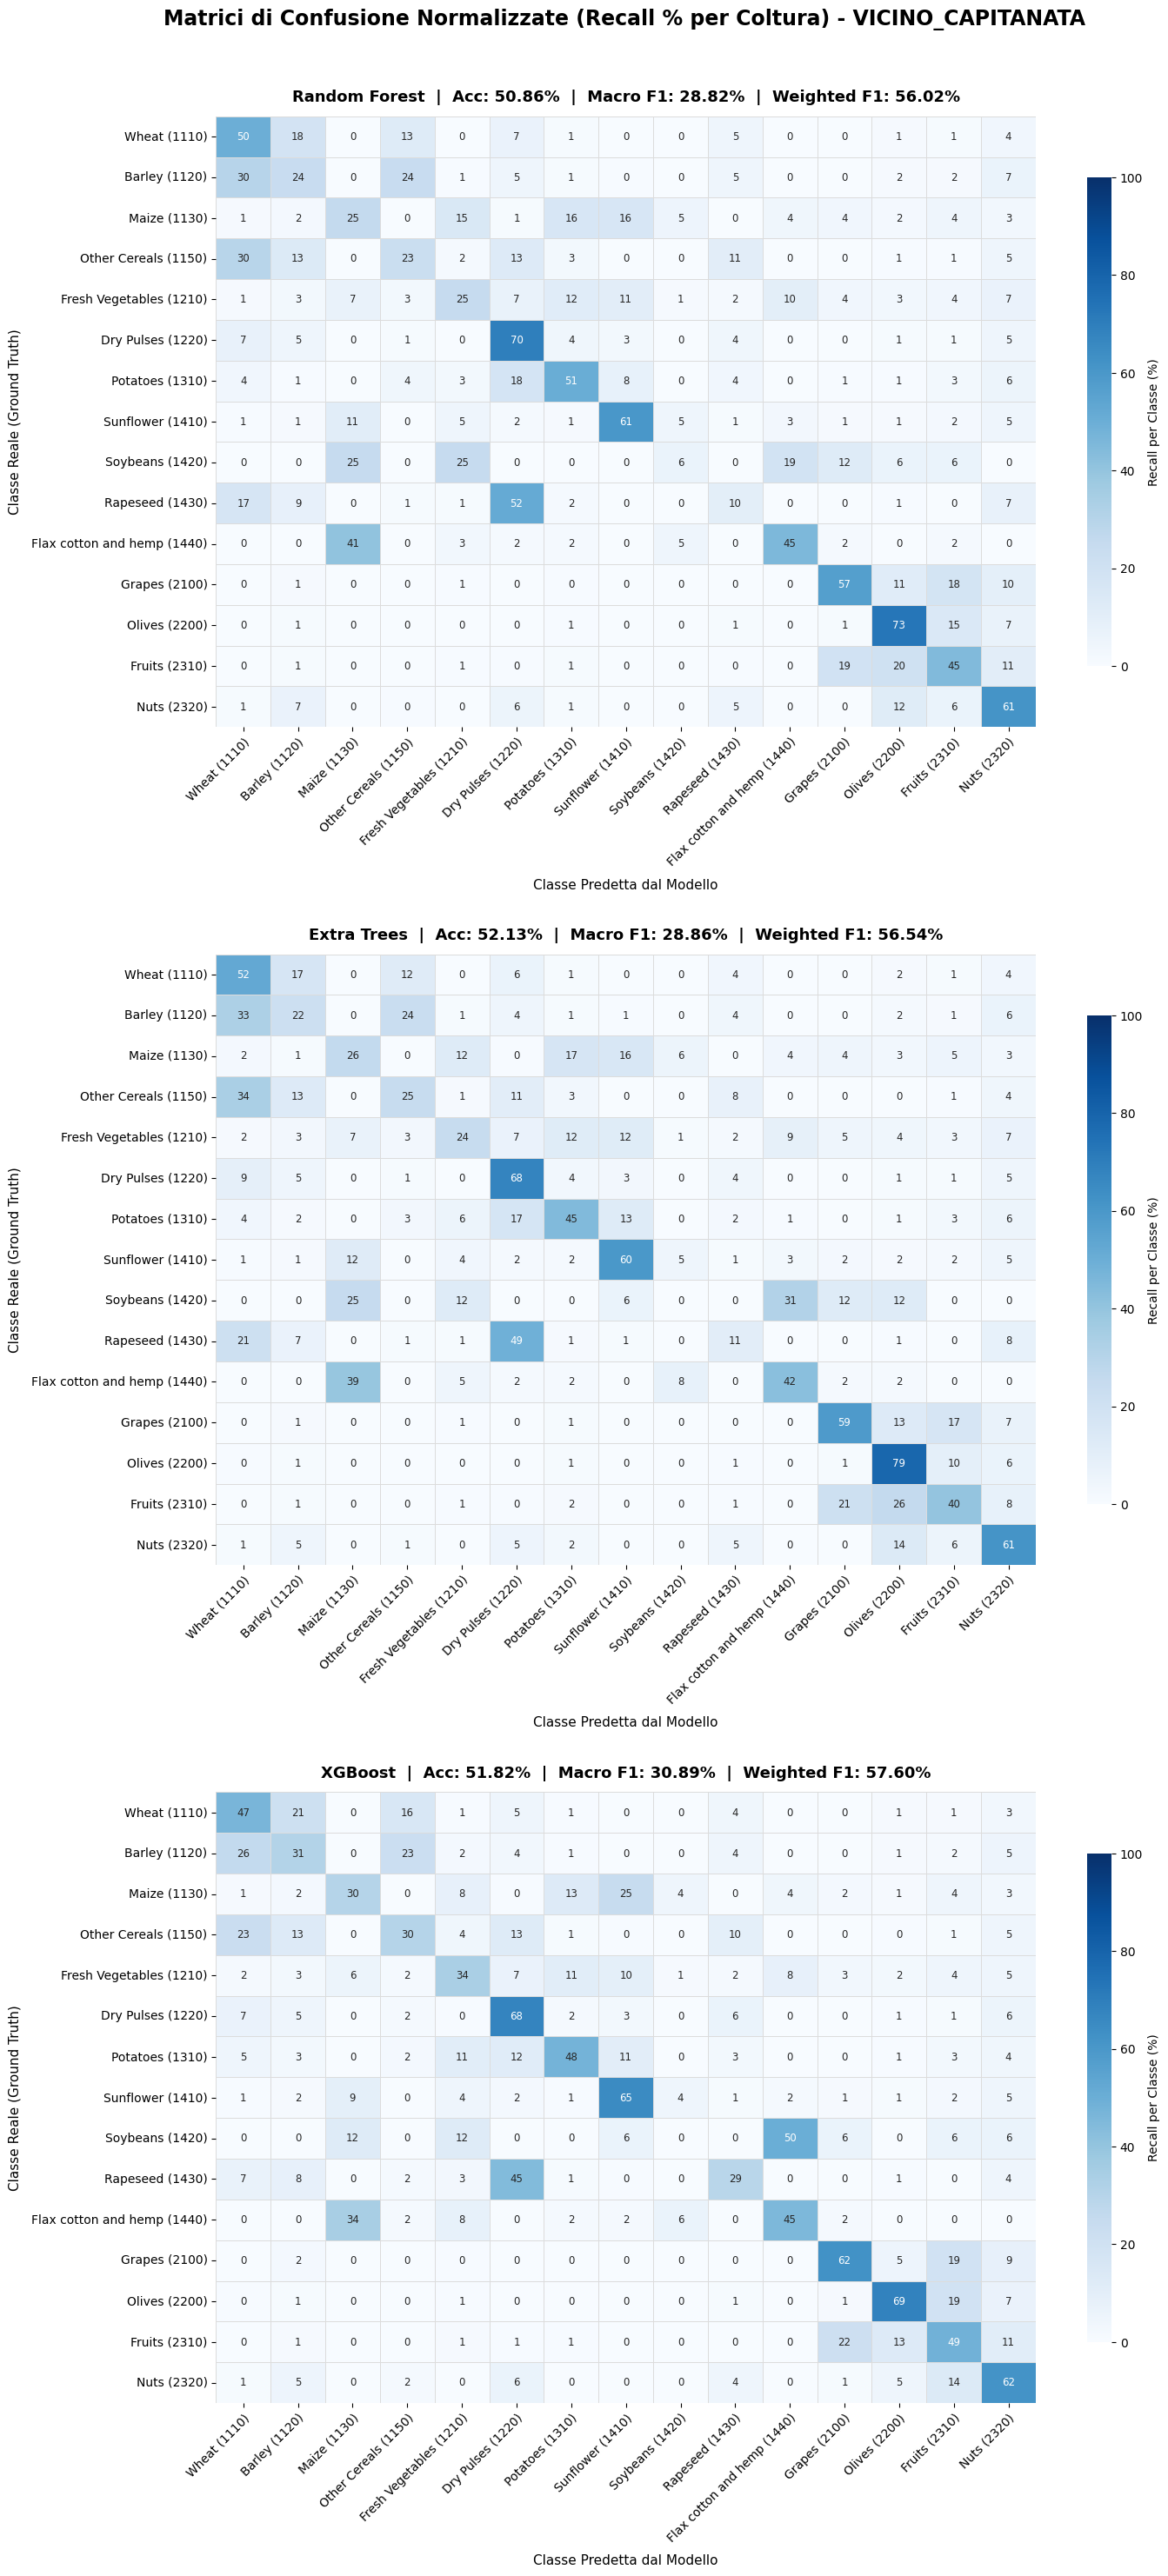

In [ ]:
import gc
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score, f1_score, confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

from src.feature_engineering import FEATURE_LIST

if "all_zones_summary" not in globals():                                                     
    all_zones_summary = {} 

# -----------------------------------------------------------------------------------------
# CARICAMENTO DATASET

zone_target = "vicino_capitanata"
dataset_path = PROCESSED_DIR / "zone_test" / "datasets" / f"dataset_{zone_target}.parquet"

if "datasets_test" in globals() and datasets_test is not None and zone_target in datasets_test:
    df_test = datasets_test[zone_target]
    print(f"Dataset '{zone_target}' trovato in memoria: {len(df_test):,} righe")
elif dataset_path.exists():
    df_test = pd.read_parquet(dataset_path)
    print(f"Dataset '{zone_target}' caricato da disco: {len(df_test):,} righe")
else:
    raise FileNotFoundError(f"Dataset non trovato in {dataset_path}.")

X_test = df_test[FEATURE_LIST]
y_test = df_test["code"].astype(int)

# Caricamento legenda colture
legend = {}
legend_path = PROCESSED_DIR / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

# ----------------------------------------------------------------------------------------
# CARICAMENTO DEI MODELLI ADDESTRATI

def load_and_predict(model_folder, X):
    folder_path = MODELS_DIR / model_folder
    target_file = folder_path / f"{model_folder}_crop_model.joblib"
    
    if not target_file.exists():
        joblib_files = list(folder_path.glob("*.joblib"))
        base_candidates = [f for f in joblib_files if "crop_model" in f.name and "pruned" not in f.name]
        target_file = sorted(base_candidates)[0] if base_candidates else (sorted(joblib_files)[0] if joblib_files else None)
    
    if not target_file or not target_file.exists():
        print(f"Nessun modello base trovato in: {folder_path.relative_to(DATA_DIR)}")
        return None
    
    print(f"Caricamento {model_folder} da Drive: {target_file.relative_to(DATA_DIR)}")
    payload = joblib.load(target_file)
    model = payload["model"]
    
    preds = model.predict(X)
    if "label_encoder" in payload and payload["label_encoder"] is not None:
        preds = payload["label_encoder"].inverse_transform(preds)
    
    del model, payload
    gc.collect()
    return preds

models_to_test = [
    ("Random Forest", "random_forest"),
    ("Extra Trees", "extra_trees"),
    ("XGBoost", "xgboost"),
]

predictions_dict = {}
for m_name, folder in models_to_test:
    preds = load_and_predict(folder, X_test)
    if preds is not None:
        predictions_dict[m_name] = preds

# ----------------------------------------------------------------------------------------
# CALCOLO METRICHE E REPORT DI CLASSIFICAZIONE

unique_classes = sorted(y_test.unique())
class_labels = [f"{legend.get(str(c), c)} ({c})" for c in unique_classes]

reports_dict = {}
summary_metrics = []

for m_name, preds in predictions_dict.items():
    acc = accuracy_score(y_test, preds)
    f1_m = f1_score(y_test, preds, average="macro", zero_division=0)
    f1_w = f1_score(y_test, preds, average="weighted", zero_division=0)
    
    summary_metrics.append({
        "Modello": m_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
        "Weighted F1 (%)": round(f1_w * 100, 2)
    })
    
    report = classification_report(
        y_test, preds, labels=unique_classes, target_names=class_labels,
        output_dict=True, zero_division=0
    )
    df_rep = pd.DataFrame(report).T.round(3)
    df_rep["support"] = df_rep["support"].astype(int)
    reports_dict[m_name] = df_rep

# ----------------------------------------------------------------------------------------
# TABELLE COMPARATIVE DELLE PRESTAZIONI

print(f"\nCONFRONTO MODELLI: {zone_target.upper()} ({len(df_test):,} campioni)")

# tabella riepilogativa globale
df_summary = pd.DataFrame(summary_metrics)
display(df_summary.style.hide(axis="index"))  

# tabella comparativa diretta F1-Score per classe colturale
if reports_dict:
    comp_f1_data = {f"F1_{m_name}": df_rep["f1-score"] for m_name, df_rep in reports_dict.items()}                                                                                                                                     
    comp_f1_df = pd.DataFrame(comp_f1_data)                                                                                                                                                                                            
    comp_f1_df["Support"] = next(iter(reports_dict.values()))["support"]
    
    print("\nConfronto dettagliato F1-Score per classe colturale:")
    display(comp_f1_df)

    all_zones_summary[zone_target] = df_summary.copy() 

# ----------------------------------------------------------------------------------------
# MATRICI DI CONFUSIONE NORMALIZZATE

fig, axes = plt.subplots(3, 1, figsize=(15, 30))                                                                                                                                                                                       
fig.suptitle(                                                                                                                                                                                                                          
    f"Matrici di Confusione Normalizzate (Recall % per Coltura) - {zone_target.upper()}",                                                                                                                                              
    fontsize=17,                                                                                                                                                                                                                       
    fontweight="bold",                                                                                                                                                                                                                 
    y=0.995,                                                                                                                                                                                                                           
)                                                                                                                                                                                                                                      
                                                                                                                                                                                                                                        
# recupero delle metriche calcolate in precedenza                                                                                                                                                            
metrics_lookup = {row["Modello"]: row for row in summary_metrics}                                                                                                                                                                      
                                                                                                                                                                                                                                        
for idx, (m_name, _) in enumerate(models_to_test):                                                                                                                                                                                     
    ax = axes[idx]
    if m_name not in predictions_dict:
        ax.set_title(f"{m_name} (Non disponibile)")
        continue
    
    preds = predictions_dict[m_name]
    cm_norm = confusion_matrix(y_test, preds, labels=unique_classes, normalize='true') * 100
    
    m_info = metrics_lookup.get(m_name, {})
    acc = m_info.get("Accuracy (%)", 0.0)
    f1_m = m_info.get("Macro F1 (%)", 0.0)
    f1_w = m_info.get("Weighted F1 (%)", 0.0)
    
    sns.heatmap(
        cm_norm,
        annot=True,
        fmt=".0f",
        annot_kws={"size": 8.5},
        cmap="Blues",
        vmin=0,
        vmax=100,
        xticklabels=class_labels,
        yticklabels=class_labels,
        cbar_kws={"label": "Recall per Classe (%)", "shrink": 0.8},
        linewidths=0.4,
        linecolor="#dcdcdc",
        ax=ax,
    )
    
    ax.set_title(
        f"{m_name}  |  Acc: {acc:.2f}%  |  Macro F1: {f1_m:.2f}%  |  Weighted F1: {f1_w:.2f}%",
        fontsize=13,
        fontweight="bold",
        pad=12,
    )
    ax.set_xlabel("Classe Predetta dal Modello", fontsize=11, labelpad=8)
    ax.set_ylabel("Classe Reale (Ground Truth)", fontsize=11, labelpad=8)
    plt.setp(ax.get_xticklabels(), rotation=45, ha="right", rotation_mode="anchor")
    plt.setp(ax.get_yticklabels(), rotation=0)

plt.tight_layout(pad=3.0)
plt.show()

# rilascio dei buffer grafici di Matplotlib
plt.close(fig)


#### Test - Jerez, Spagna

In [ ]:
import gc
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score, f1_score

from src.feature_engineering import FEATURE_LIST

# -----------------------------------------------------------------------------------------
# CARICAMENTO DATASET

zone_target = "jerez_spagna"
dataset_path = PROCESSED_DIR / "zone_test" / "datasets" / f"dataset_{zone_target}.parquet"

if "datasets_test" in globals() and datasets_test is not None and zone_target in datasets_test:
    df_test = datasets_test[zone_target]
    print(f"Dataset '{zone_target}' trovato in memoria: {len(df_test):,} righe")
elif dataset_path.exists():
    df_test = pd.read_parquet(dataset_path)
    print(f"Dataset '{zone_target}' caricato da disco: {len(df_test):,} righe")
else:
    raise FileNotFoundError(f"Dataset non trovato in {dataset_path}.")

X_test = df_test[FEATURE_LIST]
y_test = df_test["code"].astype(int)

# Caricamento legenda colture
legend = {}
legend_path = PROCESSED_DIR / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

# ----------------------------------------------------------------------------------------
# CARICAMENTO DEI MODELLI ADDESTRATI

def load_and_predict(model_folder, X):
    folder_path = MODELS_DIR / model_folder
    target_file = folder_path / f"{model_folder}_crop_model.joblib"
    
    if not target_file.exists():
        joblib_files = list(folder_path.glob("*.joblib"))
        base_candidates = [f for f in joblib_files if "crop_model" in f.name and "pruned" not in f.name]
        target_file = sorted(base_candidates)[0] if base_candidates else (sorted(joblib_files)[0] if joblib_files else None)
    
    if not target_file or not target_file.exists():
        print(f"Nessun modello base trovato in: {folder_path.relative_to(DATA_DIR)}")
        return None
    
    print(f"Caricamento {model_folder} da Drive: {target_file.relative_to(DATA_DIR)}")
    payload = joblib.load(target_file)
    model = payload["model"]
    
    preds = model.predict(X)
    if "label_encoder" in payload and payload["label_encoder"] is not None:
        preds = payload["label_encoder"].inverse_transform(preds)
    
    del model, payload
    gc.collect()
    return preds

models_to_test = [
    ("Random Forest", "random_forest"),
    ("Extra Trees", "extra_trees"),
    ("XGBoost", "xgboost"),
]

predictions_dict = {}
for m_name, folder in models_to_test:
    preds = load_and_predict(folder, X_test)
    if preds is not None:
        predictions_dict[m_name] = preds

# ----------------------------------------------------------------------------------------
# CALCOLO METRICHE E REPORT DI CLASSIFICAZIONE

unique_classes = sorted(y_test.unique())
class_labels = [f"{legend.get(str(c), c)} ({c})" for c in unique_classes]

reports_dict = {}
summary_metrics = []

for m_name, preds in predictions_dict.items():
    acc = accuracy_score(y_test, preds)
    f1_m = f1_score(y_test, preds, average="macro", zero_division=0)
    f1_w = f1_score(y_test, preds, average="weighted", zero_division=0)
    
    summary_metrics.append({
        "Modello": m_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
        "Weighted F1 (%)": round(f1_w * 100, 2)
    })
    
    report = classification_report(
        y_test, preds, labels=unique_classes, target_names=class_labels,
        output_dict=True, zero_division=0
    )
    df_rep = pd.DataFrame(report).T.round(3)
    df_rep["support"] = df_rep["support"].astype(int)
    reports_dict[m_name] = df_rep

# ----------------------------------------------------------------------------------------
# TABELLE COMPARATIVE DELLE PRESTAZIONI

print(f"\nCONFRONTO MODELLI: {zone_target.upper()} ({len(df_test):,} campioni)")

# tabella riepilogativa globale
df_summary = pd.DataFrame(summary_metrics)
display(df_summary.style.hide(axis="index"))  

# tabella comparativa diretta F1-Score per classe colturale
if reports_dict:
    comp_f1_data = {f"F1_{m_name}": df_rep["f1-score"] for m_name, df_rep in reports_dict.items()}                                                                                                                                     
    comp_f1_df = pd.DataFrame(comp_f1_data)                                                                                                                                                                                            
    comp_f1_df["Support"] = next(iter(reports_dict.values()))["support"]
    
    print("\nConfronto dettagliato F1-Score per classe colturale:")
    display(comp_f1_df)

    all_zones_summary[zone_target] = df_summary.copy() 

# rilascio finale memoria
del df_test, X_test, y_test, predictions_dict
gc.collect()

Dataset 'jerez_spagna' trovato in memoria: 100,000 righe
Caricamento random_forest da Drive: models/random_forest/random_forest_crop_model.joblib
Caricamento extra_trees da Drive: models/extra_trees/extra_trees_crop_model.joblib
Caricamento xgboost da Drive: models/xgboost/xgboost_crop_model.joblib

CONFRONTO MODELLI: JEREZ_SPAGNA (100,000 campioni)


Modello,Accuracy (%),Macro F1 (%),Weighted F1 (%)
Random Forest,28.340000,23.170000,25.020000
Extra Trees,28.410000,24.200000,25.430000
XGBoost,28.050000,23.650000,25.380000



Confronto dettagliato F1-Score per classe colturale:


,F1_Random Forest,F1_Extra Trees,F1_XGBoost,Support
Wheat (1110),0.020,0.024,0.022,23774
Barley (1120),0.130,0.132,0.118,3761
Maize (1130),0.265,0.284,0.287,1717
Rice (1140),0.356,0.488,0.419,547
Other Cereals (1150),0.355,0.359,0.358,12360
Fresh Vegetables (1210),0.233,0.233,0.263,10558
Dry Pulses (1220),0.297,0.267,0.274,7114
Potatoes (1310),0.107,0.103,0.117,827
Sunflower (1410),0.153,0.159,0.165,18461
Soybeans (1420),0.000,0.000,0.000,9


130

#### Test - Albacete, Spagna

In [ ]:
import gc
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score, f1_score

from src.feature_engineering import FEATURE_LIST

# -----------------------------------------------------------------------------------------
# CARICAMENTO DATASET

zone_target = "albacete_spagna"
dataset_path = PROCESSED_DIR / "zone_test" / "datasets" / f"dataset_{zone_target}.parquet"

if "datasets_test" in globals() and datasets_test is not None and zone_target in datasets_test:
    df_test = datasets_test[zone_target]
    print(f"Dataset '{zone_target}' trovato in memoria: {len(df_test):,} righe")
elif dataset_path.exists():
    df_test = pd.read_parquet(dataset_path)
    print(f"Dataset '{zone_target}' caricato da disco: {len(df_test):,} righe")
else:
    raise FileNotFoundError(f"Dataset non trovato in {dataset_path}.")

X_test = df_test[FEATURE_LIST]
y_test = df_test["code"].astype(int)

# Caricamento legenda colture
legend = {}
legend_path = PROCESSED_DIR / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

# ----------------------------------------------------------------------------------------
# CARICAMENTO DEI MODELLI ADDESTRATI

def load_and_predict(model_folder, X):
    folder_path = MODELS_DIR / model_folder
    target_file = folder_path / f"{model_folder}_crop_model.joblib"
    
    if not target_file.exists():
        joblib_files = list(folder_path.glob("*.joblib"))
        base_candidates = [f for f in joblib_files if "crop_model" in f.name and "pruned" not in f.name]
        target_file = sorted(base_candidates)[0] if base_candidates else (sorted(joblib_files)[0] if joblib_files else None)
    
    if not target_file or not target_file.exists():
        print(f"Nessun modello base trovato in: {folder_path.relative_to(DATA_DIR)}")
        return None
    
    print(f"Caricamento {model_folder} da Drive: {target_file.relative_to(DATA_DIR)}")
    payload = joblib.load(target_file)
    model = payload["model"]
    
    preds = model.predict(X)
    if "label_encoder" in payload and payload["label_encoder"] is not None:
        preds = payload["label_encoder"].inverse_transform(preds)
    
    del model, payload
    gc.collect()
    return preds

models_to_test = [
    ("Random Forest", "random_forest"),
    ("Extra Trees", "extra_trees"),
    ("XGBoost", "xgboost"),
]

predictions_dict = {}
for m_name, folder in models_to_test:
    preds = load_and_predict(folder, X_test)
    if preds is not None:
        predictions_dict[m_name] = preds

# ----------------------------------------------------------------------------------------
# CALCOLO METRICHE E REPORT DI CLASSIFICAZIONE

unique_classes = sorted(y_test.unique())
class_labels = [f"{legend.get(str(c), c)} ({c})" for c in unique_classes]

reports_dict = {}
summary_metrics = []

for m_name, preds in predictions_dict.items():
    acc = accuracy_score(y_test, preds)
    f1_m = f1_score(y_test, preds, average="macro", zero_division=0)
    f1_w = f1_score(y_test, preds, average="weighted", zero_division=0)
    
    summary_metrics.append({
        "Modello": m_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
        "Weighted F1 (%)": round(f1_w * 100, 2)
    })
    
    report = classification_report(
        y_test, preds, labels=unique_classes, target_names=class_labels,
        output_dict=True, zero_division=0
    )
    df_rep = pd.DataFrame(report).T.round(3)
    df_rep["support"] = df_rep["support"].astype(int)
    reports_dict[m_name] = df_rep

# ----------------------------------------------------------------------------------------
# TABELLE COMPARATIVE DELLE PRESTAZIONI

print(f"\nCONFRONTO MODELLI: {zone_target.upper()} ({len(df_test):,} campioni)")

# tabella riepilogativa globale
df_summary = pd.DataFrame(summary_metrics)
display(df_summary.style.hide(axis="index"))  

# tabella comparativa diretta F1-Score per classe colturale
if reports_dict:
    comp_f1_data = {f"F1_{m_name}": df_rep["f1-score"] for m_name, df_rep in reports_dict.items()}                                                                                                                                     
    comp_f1_df = pd.DataFrame(comp_f1_data)                                                                                                                                                                                            
    comp_f1_df["Support"] = next(iter(reports_dict.values()))["support"]
    
    print("\nConfronto dettagliato F1-Score per classe colturale:")
    display(comp_f1_df)

    all_zones_summary[zone_target] = df_summary.copy()                                           

# rilascio finale memoria
del df_test, X_test, y_test, predictions_dict
gc.collect()

Dataset 'albacete_spagna' trovato in memoria: 100,000 righe
Caricamento random_forest da Drive: models/random_forest/random_forest_crop_model.joblib
Caricamento extra_trees da Drive: models/extra_trees/extra_trees_crop_model.joblib
Caricamento xgboost da Drive: models/xgboost/xgboost_crop_model.joblib

CONFRONTO MODELLI: ALBACETE_SPAGNA (100,000 campioni)


Modello,Accuracy (%),Macro F1 (%),Weighted F1 (%)
Random Forest,29.180000,24.620000,31.390000
Extra Trees,29.590000,24.460000,31.760000
XGBoost,36.160000,25.090000,38.640000



Confronto dettagliato F1-Score per classe colturale:


,F1_Random Forest,F1_Extra Trees,F1_XGBoost,Support
Wheat (1110),0.307,0.316,0.167,7980
Barley (1120),0.444,0.467,0.493,22996
Maize (1130),0.670,0.654,0.633,1908
Other Cereals (1150),0.155,0.157,0.229,15973
Fresh Vegetables (1210),0.063,0.066,0.113,4378
Dry Pulses (1220),0.371,0.402,0.389,5921
Potatoes (1310),0.192,0.180,0.118,194
Sunflower (1410),0.022,0.020,0.031,449
Rapeseed (1430),0.660,0.624,0.660,885
Flax cotton and hemp (1440),0.000,0.001,0.001,7


130

#### Test - Rovato, Brescia

In [ ]:
import gc
import json
import joblib
import numpy as np
import pandas as pd
from IPython.display import display
from sklearn.metrics import classification_report, accuracy_score, f1_score

from src.feature_engineering import FEATURE_LIST

# -----------------------------------------------------------------------------------------
# CARICAMENTO DATASET

zone_target = "rovato"
dataset_path = PROCESSED_DIR / "zone_test" / "datasets" / f"dataset_{zone_target}.parquet"

if "datasets_test" in globals() and datasets_test is not None and zone_target in datasets_test:
    df_test = datasets_test[zone_target]
    print(f"Dataset '{zone_target}' trovato in memoria: {len(df_test):,} righe")
elif dataset_path.exists():
    df_test = pd.read_parquet(dataset_path)
    print(f"Dataset '{zone_target}' caricato da disco: {len(df_test):,} righe")
else:
    raise FileNotFoundError(f"Dataset non trovato in {dataset_path}.")

X_test = df_test[FEATURE_LIST]
y_test = df_test["code"].astype(int)

# Caricamento legenda colture
legend = {}
legend_path = PROCESSED_DIR / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

# ----------------------------------------------------------------------------------------
# CARICAMENTO DEI MODELLI ADDESTRATI

def load_and_predict(model_folder, X):
    folder_path = MODELS_DIR / model_folder
    target_file = folder_path / f"{model_folder}_crop_model.joblib"
    
    if not target_file.exists():
        joblib_files = list(folder_path.glob("*.joblib"))
        base_candidates = [f for f in joblib_files if "crop_model" in f.name and "pruned" not in f.name]
        target_file = sorted(base_candidates)[0] if base_candidates else (sorted(joblib_files)[0] if joblib_files else None)
    
    if not target_file or not target_file.exists():
        print(f"Nessun modello base trovato in: {folder_path.relative_to(DATA_DIR)}")
        return None
    
    print(f"Caricamento {model_folder} da Drive: {target_file.relative_to(DATA_DIR)}")
    payload = joblib.load(target_file)
    model = payload["model"]
    
    preds = model.predict(X)
    if "label_encoder" in payload and payload["label_encoder"] is not None:
        preds = payload["label_encoder"].inverse_transform(preds)
    
    del model, payload
    gc.collect()
    return preds

models_to_test = [
    ("Random Forest", "random_forest"),
    ("Extra Trees", "extra_trees"),
    ("XGBoost", "xgboost"),
]

predictions_dict = {}
for m_name, folder in models_to_test:
    preds = load_and_predict(folder, X_test)
    if preds is not None:
        predictions_dict[m_name] = preds

# ----------------------------------------------------------------------------------------
# CALCOLO METRICHE E REPORT DI CLASSIFICAZIONE

unique_classes = sorted(y_test.unique())
class_labels = [f"{legend.get(str(c), c)} ({c})" for c in unique_classes]

reports_dict = {}
summary_metrics = []

for m_name, preds in predictions_dict.items():
    acc = accuracy_score(y_test, preds)
    f1_m = f1_score(y_test, preds, average="macro", zero_division=0)
    f1_w = f1_score(y_test, preds, average="weighted", zero_division=0)
    
    summary_metrics.append({
        "Modello": m_name,
        "Accuracy (%)": round(acc * 100, 2),
        "Macro F1 (%)": round(f1_m * 100, 2),
        "Weighted F1 (%)": round(f1_w * 100, 2)
    })
    
    report = classification_report(
        y_test, preds, labels=unique_classes, target_names=class_labels,
        output_dict=True, zero_division=0
    )
    df_rep = pd.DataFrame(report).T.round(3)
    df_rep["support"] = df_rep["support"].astype(int)
    reports_dict[m_name] = df_rep

# ----------------------------------------------------------------------------------------
# TABELLE COMPARATIVE DELLE PRESTAZIONI

print(f"\nCONFRONTO MODELLI: {zone_target.upper()} ({len(df_test):,} campioni)")

# tabella riepilogativa globale
df_summary = pd.DataFrame(summary_metrics)
display(df_summary.style.hide(axis="index"))  

# tabella comparativa diretta F1-Score per classe colturale
if reports_dict:
    comp_f1_data = {f"F1_{m_name}": df_rep["f1-score"] for m_name, df_rep in reports_dict.items()}                                                                                                                                     
    comp_f1_df = pd.DataFrame(comp_f1_data)                                                                                                                                                                                            
    comp_f1_df["Support"] = next(iter(reports_dict.values()))["support"]
    
    print("\nConfronto dettagliato F1-Score per classe colturale:")
    display(comp_f1_df)
        
    all_zones_summary[zone_target] = df_summary.copy()                                           


# rilascio finale memoria
del df_test, X_test, y_test, predictions_dict
gc.collect()

Dataset 'rovato' trovato in memoria: 100,000 righe
Caricamento random_forest da Drive: models/random_forest/random_forest_crop_model.joblib
Caricamento extra_trees da Drive: models/extra_trees/extra_trees_crop_model.joblib
Caricamento xgboost da Drive: models/xgboost/xgboost_crop_model.joblib

CONFRONTO MODELLI: ROVATO (100,000 campioni)


Modello,Accuracy (%),Macro F1 (%),Weighted F1 (%)
Random Forest,38.040000,13.460000,42.840000
Extra Trees,37.140000,12.860000,41.980000
XGBoost,40.300000,14.750000,44.870000



Confronto dettagliato F1-Score per classe colturale:


,F1_Random Forest,F1_Extra Trees,F1_XGBoost,Support
Wheat (1110),0.507,0.461,0.508,19075
Barley (1120),0.150,0.150,0.171,6667
Maize (1130),0.569,0.572,0.592,50884
Rice (1140),0.035,0.019,0.039,720
Other Cereals (1150),0.035,0.031,0.023,502
Fresh Vegetables (1210),0.207,0.199,0.261,6982
Dry Pulses (1220),0.162,0.156,0.162,616
Potatoes (1310),0.014,0.013,0.018,175
Sugar Beet (1320),0.000,0.000,0.000,111
Sunflower (1410),0.052,0.052,0.059,784


130

#### Confronto prestazioni modelli-zone di test

In [ ]:
import pandas as pd                                                                          
                                                                                                 
if "summary_zones" not in globals() or not all_zones_summary:                                    
    raise ValueError("Il dizionario 'all_zones_summary' è vuoto o non definito.")                                                                                        
                                                                                                                               
zone_labels = {                                                                              
    "vicino_capitanata": "Vicino Capitanata",                                                
    "albacete_spagna": "Albacete (Spagna)",                                                  
    "jerez_spagna": "Jerez (Spagna)",                                                        
    "rovato": "Rovato (Brescia)",                                                            
}                                                                                            
                                                                                                
models = ["Random Forest", "Extra Trees", "XGBoost"]                                         
                                                                                                                                             
metrics_to_show = [                                                                          
    (                                                                                        
        "Macro F1 (%)",                                                                      
        "CONFRONTO MACRO F1 (%) - Media non ponderata tra tutte le classi",               
    ),                                                                                       
    (                                                                                        
        "Weighted F1 (%)",                                                                   
        "CONFRONTO WEIGHTED F1 (%) - Ponderato sulla frequenza delle colture",            
    ),                                                                                       
    (                                                                                        
        "Accuracy (%)",                                                                      
        "CONFRONTO ACCURACY (%) - Percentuale totale di campioni corretti",               
    ),                                                                                       
]                                                                                            
                                                                                                
for metric_col, title in metrics_to_show:                                                    
    rows = []                                                                                
    for m in models:                                                                         
        row = {"Modello": m}                                                                 
        for z_key, z_label in zone_labels.items():                                           
            if z_key in all_zones_summary:                                                       
                df_z = all_zones_summary[z_key]                                                  
                val = df_z.loc[df_z["Modello"] == m, metric_col].values[0]                   
                row[z_label] = val                                                           
        rows.append(row)

    df_metric = pd.DataFrame(rows)

    print("=" * 80)
    print(title)
    print("=" * 80)
    display(df_metric.style.hide(axis="index"))
    print("\n")


#### Mappe della zona Vicino Capitanata con XGBoost

Inizializzazione rendering cartografico ad alta risoluzione (Vicino Capitanata)...
Caricamento dataset test da disco: dataset_vicino_capitanata.parquet
Caricamento modello XGBoost da disco...
Inferenza sui 100,000 punti con modello XGBoost...
Raster di riferimento caricato: 9176x12240 pixel (CRS: EPSG:4326).
Ritaglio cartografico effettuato: 3595x11511 pixel (rimossi 5581 pixel di mare aperto a nord).
Generazione dei 3 canvas cartografici ad alta visibilità...


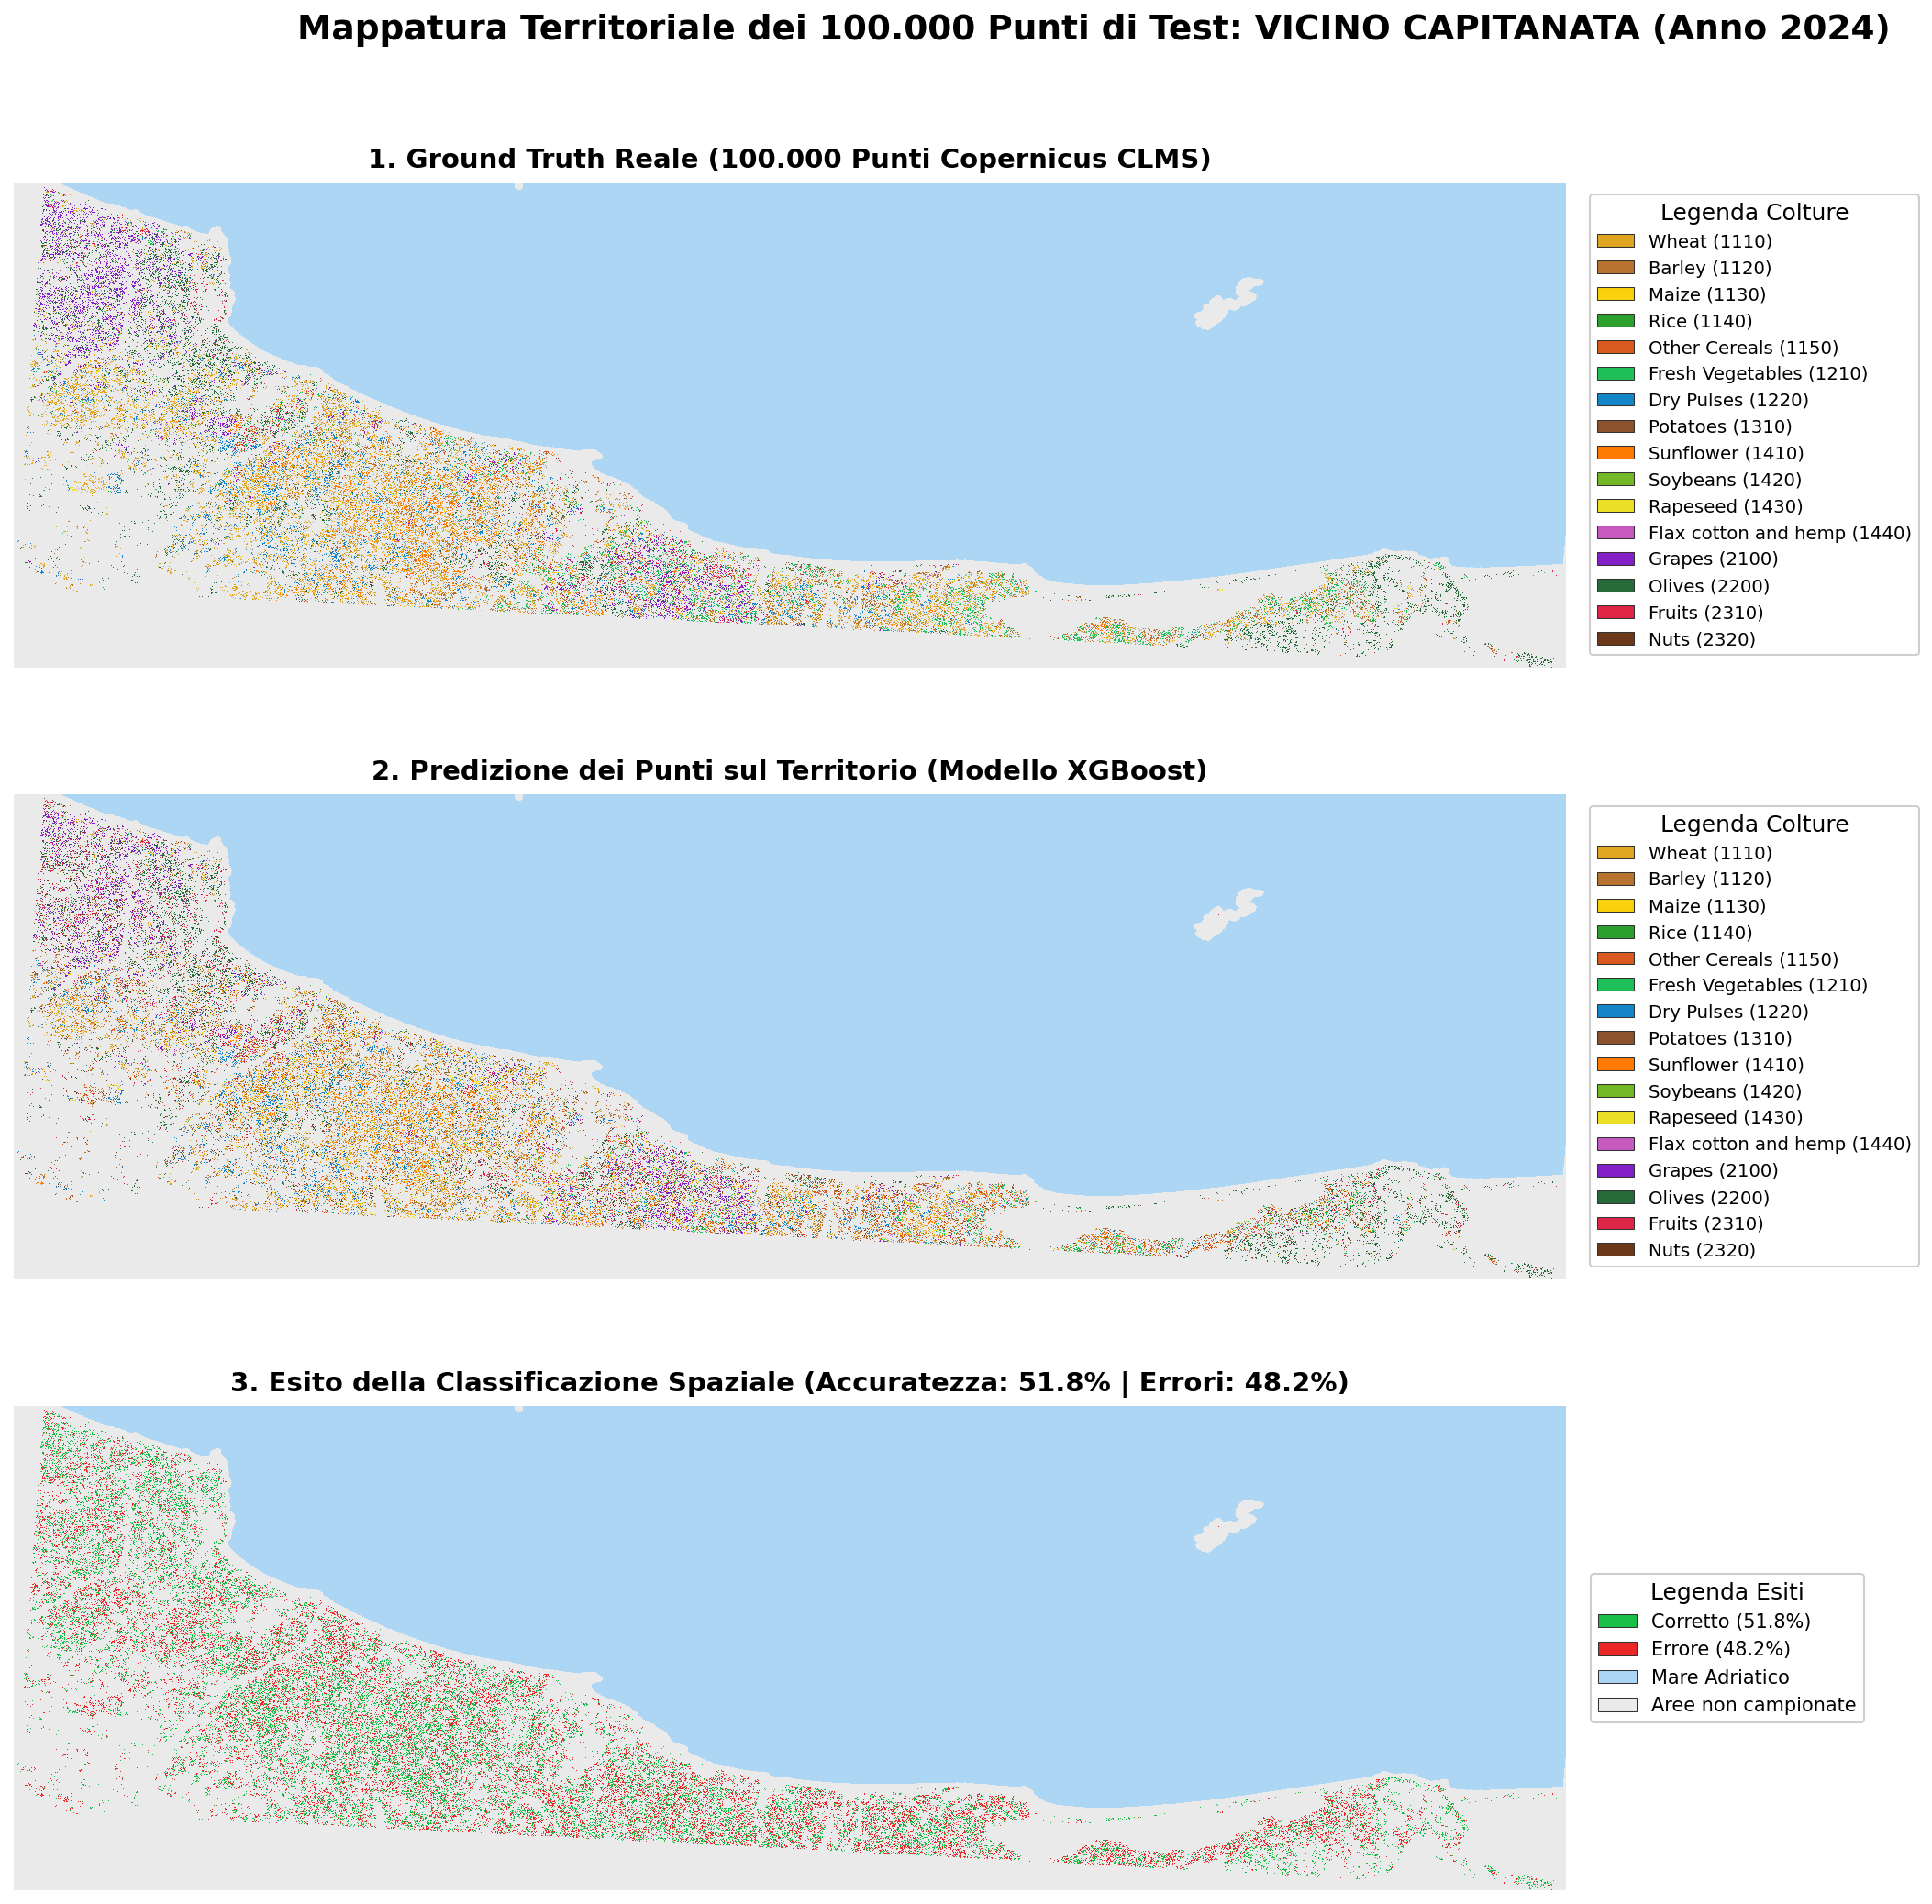

10503

In [4]:
import gc
import json
import joblib
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.patches import Patch
import rasterio
from rasterio.crs import CRS
from rasterio.enums import Resampling
from rasterio.merge import merge
from rasterio.warp import transform

from src.feature_engineering import FEATURE_LIST

print("Inizializzazione rendering cartografico ad alta risoluzione (Vicino Capitanata)...")

# ==============================================================================
# 1. RECUPERO PUNTI DI TEST (100.000 CAMPIONI) E PREDIZIONI XGBOOST
# ==============================================================================
if "df_test" in globals() and "zone_target" in globals() and zone_target == "vicino_capitanata":
    df_pts = df_test
elif "datasets_test" in globals() and "vicino_capitanata" in datasets_test:
    df_pts = datasets_test["vicino_capitanata"]
else:
    p_path = DATA_DIR / "processed" / "zone_test" / "datasets" / "dataset_vicino_capitanata.parquet"
    if not p_path.exists():
        raise FileNotFoundError(f"Dataset non trovato in: {p_path}")
    print(f"Caricamento dataset test da disco: {p_path.name}")
    df_pts = pd.read_parquet(p_path)

lons = df_pts["lon"].values
lats = df_pts["lat"].values
y_true = df_pts["code"].values

if "predictions_dict" in globals() and "XGBoost" in predictions_dict:
    preds_xgb = np.array(predictions_dict["XGBoost"])
    print("Predizioni XGBoost recuperate dalla sessione corrente.")
else:
    print("Caricamento modello XGBoost da disco...")
    xgb_dir = MODELS_DIR / "xgboost"
    xgb_candidates = sorted(list(xgb_dir.glob("*.joblib")))
    base_xgb = [f for f in xgb_candidates if "crop_model" in f.name and "pruned" not in f.name]
    target_xgb = base_xgb[0] if base_xgb else (xgb_candidates[0] if xgb_candidates else None)
    
    if not target_xgb or not target_xgb.exists():
        raise FileNotFoundError(f"Modello XGBoost non trovato in: {xgb_dir}")
        
    payload = joblib.load(target_xgb)
    model_xgb = payload["model"]
    feat_cols = [c for c in FEATURE_LIST if c in df_pts.columns]
    X_pts = df_pts[feat_cols]
    
    print(f"Inferenza sui {len(df_pts):,} punti con modello XGBoost...")
    preds_xgb = model_xgb.predict(X_pts)
    if payload.get("label_encoder") is not None:
        preds_xgb = payload["label_encoder"].inverse_transform(preds_xgb)
    del model_xgb, payload
    gc.collect()

# ==============================================================================
# 2. CARICAMENTO DEL RASTER DI RIFERIMENTO COPERNICUS (PER CONFINI E MASCHERA MARE)
# ==============================================================================
gt_files = []
if "tifs_4326" in globals() and "vicino_capitanata" in tifs_4326:
    gt_files = [f for f in tifs_4326["vicino_capitanata"] if "sentinel" not in str(f).lower()]

if not gt_files:
    gt_files = [
        str(f) for f in (DATA_DIR / "processed" / "zone_test").rglob("*.tif")
        if "vicino_capitanata" in str(f).lower() and "sentinel" not in str(f).lower()
    ]

if not gt_files:
    gt_files = [
        str(f) for f in (DATA_DIR / "raw" / "zone_test").rglob("*.tif")
        if "vicino_capitanata" in str(f).lower() and "sentinel" not in str(f).lower()
    ]

if not gt_files:
    raise FileNotFoundError("Nessun file raster Copernicus (1 banda) trovato per Vicino Capitanata.")

if len(gt_files) > 1:
    src_list = [rasterio.open(f) for f in gt_files]
    gt_mosaic, raster_transform = merge(src_list, resampling=Resampling.nearest)
    raster_crs = src_list[0].crs
    for s in src_list:
        s.close()
    gt_raster = gt_mosaic.squeeze()
else:
    with rasterio.open(gt_files[0]) as s:
        gt_raster = s.read(1)
        raster_transform = s.transform
        raster_crs = s.crs

h_orig, w_orig = gt_raster.shape
print(f"Raster di riferimento caricato: {h_orig}x{w_orig} pixel (CRS: {raster_crs}).")

if raster_crs != CRS.from_epsg(4326):
    xs, ys = transform(CRS.from_epsg(4326), raster_crs, lons, lats)
else:
    xs, ys = lons, lats

p_rows, p_cols = rasterio.transform.rowcol(raster_transform, xs, ys)
p_rows = np.clip(np.array(p_rows), 0, h_orig - 2)
p_cols = np.clip(np.array(p_cols), 0, w_orig - 2)

# ==============================================================================
# 3. RITAGLIO INTELLIGENTE DEL MARE APERTO A NORD
# ==============================================================================
min_r = max(0, int(np.min(p_rows)) - 35)
max_r = min(h_orig, int(np.max(p_rows)) + 35)
min_c = max(0, int(np.min(p_cols)) - 35)
max_c = min(w_orig, int(np.max(p_cols)) + 35)

cropped_gt = gt_raster[min_r:max_r, min_c:max_c]
ch, cw = cropped_gt.shape
rel_rows = p_rows - min_r
rel_cols = p_cols - min_c

print(f"Ritaglio cartografico effettuato: {ch}x{cw} pixel (rimossi {min_r} pixel di mare aperto a nord).")

# ==============================================================================
# 4. PALETTE COLORI AD ALTO CONTRASTO E BRILLANTEZZA PER LE COLTURE
# ==============================================================================
HIGH_CONTRAST_CROPS = {
    1110: [0.88, 0.65, 0.12],  # Frumento (Wheat): Giallo Oro caldo / Ambra (massima visibilità)
    1120: [0.72, 0.45, 0.18],  # Orzo (Barley): Bronzo caldo
    1130: [0.98, 0.82, 0.05],  # Mais (Maize): Giallo Mais brillante
    1150: [0.85, 0.35, 0.12],  # Altri cereali (Other Cereals): Terracotta
    1210: [0.12, 0.75, 0.35],  # Ortaggi (Fresh Vegetables): Verde Smeraldo brillante
    1220: [0.08, 0.52, 0.78],  # Legumi secchi (Dry Pulses): Turchese profondo
    1310: [0.55, 0.32, 0.18],  # Patate (Potatoes): Terra / Marrone
    1410: [1.00, 0.48, 0.00],  # Girasole (Sunflower): Arancione solare vivo
    1420: [0.45, 0.72, 0.15],  # Soia (Soybeans): Verde lime
    1430: [0.92, 0.88, 0.15],  # Colza (Rapeseed): Giallo limone
    1440: [0.78, 0.35, 0.75],  # Lino/Cotone/Canapa: Magenta / Orchidea
    2100: [0.52, 0.12, 0.78],  # Vigneti (Grapes): Viola uva intenso
    2200: [0.15, 0.42, 0.22],  # Oliveti (Olives): Verde oliva scuro mediterraneo
    2310: [0.88, 0.15, 0.28],  # Frutteti (Fruits): Rosso carminio / Rubino
    2320: [0.42, 0.22, 0.10],  # Frutta a guscio (Nuts): Marrone noce
}

color_map = dict(HIGH_CONTRAST_CROPS)

unique_classes = sorted(list(set(y_true).union(set(preds_xgb))))
cmap_fb = plt.colormaps["tab20"].resampled(len(unique_classes))
for i, c in enumerate(unique_classes):
    if c not in color_map:
        color_map[c] = list(cmap_fb(i)[:3])

legend = {}
legend_path = DATA_DIR / "processed" / "legend.json"
if legend_path.exists():
    with open(legend_path, "r", encoding="utf-8") as f:
        legend = json.load(f)

gt_colors = np.array([color_map.get(c, [0.5, 0.5, 0.5]) for c in y_true])
pred_colors = np.array([color_map.get(c, [0.5, 0.5, 0.5]) for c in preds_xgb])

correct_mask = (y_true == preds_xgb)
total_pts = len(y_true)
spatial_acc = (np.sum(correct_mask) / total_pts) * 100
error_rate = 100.0 - spatial_acc

diff_colors = np.where(
    correct_mask[:, None],
    np.array([0.10, 0.75, 0.28]),
    np.array([0.92, 0.15, 0.15]),
)

# ==============================================================================
# 5. GENERAZIONE DEI 3 CANVAS CARTOGRAFICI CON FOOTPRINT 5x5 SOLIDO
# ==============================================================================
def create_thematic_canvas(point_colors):
    # Sfondo grigio chiaro neutro per aree non campionate / non agricole
    canvas = np.ones((ch, cw, 3), dtype=np.float32) * 0.92
    
    # Mare Adriatico in azzurro pastello tenue
    canvas[cropped_gt == 65534] = [0.68, 0.84, 0.96]
    
    # Footprint 5x5 solido (50m x 50m) per rendere ciascun punto nitido, brillante e denso
    for dr in range(-2, 3):
        for dc in range(-2, 3):
            rr = np.clip(rel_rows + dr, 0, ch - 1)
            cc = np.clip(rel_cols + dc, 0, cw - 1)
            canvas[rr, cc] = point_colors
            
    return canvas

print("Generazione dei 3 canvas cartografici ad alta visibilità...")
canvas_gt = create_thematic_canvas(gt_colors)
canvas_pred = create_thematic_canvas(pred_colors)
canvas_diff = create_thematic_canvas(diff_colors)

# ==============================================================================
# 6. PLOT VERTICALE AD ALTA DEFINIZIONE (PROPORZIONI PERFETTE, ZERO SPAZI BIANCHI)
# ==============================================================================
# Calcolo dinamico dell'altezza esatta della figura in base alle proporzioni dell'area ritagliata
aspect_ratio = ch / cw
fig_width = 16.0
ax_width = fig_width * 0.82
ax_height = ax_width * aspect_ratio
fig_height = round(ax_height * 3 + 2.0, 1)

fig, axes = plt.subplots(3, 1, figsize=(fig_width, fig_height), dpi=150, facecolor="white")
fig.suptitle(
    "Mappatura Territoriale dei 100.000 Punti di Test: VICINO CAPITANATA (Anno 2024)",
    fontsize=18,
    fontweight="bold",
    y=0.995,
)

legend_crops = [
    Patch(
        facecolor=color_map[c],
        edgecolor="#333333",
        linewidth=0.5,
        label=f"{legend.get(str(c), f'Classe {c}')} ({c})"
    )
    for c in unique_classes
]

legend_outcomes = [
    Patch(facecolor=[0.10, 0.75, 0.28], edgecolor="#333333", linewidth=0.5, label=f"Corretto ({spatial_acc:.1f}%)"),
    Patch(facecolor=[0.92, 0.15, 0.15], edgecolor="#333333", linewidth=0.5, label=f"Errore ({error_rate:.1f}%)"),
    Patch(facecolor=[0.68, 0.84, 0.96], edgecolor="#333333", linewidth=0.5, label="Mare Adriatico"),
    Patch(facecolor=[0.92, 0.92, 0.92], edgecolor="#333333", linewidth=0.5, label="Aree non campionate"),
]

# Mappa 1: Ground Truth Reale
axes[0].imshow(canvas_gt, interpolation="nearest")
axes[0].set_title("1. Ground Truth Reale (100.000 Punti Copernicus CLMS)", fontsize=14, fontweight="bold", pad=8)
axes[0].axis("off")
axes[0].legend(
    handles=legend_crops,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    title="Legenda Colture",
    title_fontsize=12,
    fontsize=9.5,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
)

# Mappa 2: Predizione XGBoost
axes[1].imshow(canvas_pred, interpolation="nearest")
axes[1].set_title("2. Predizione dei Punti sul Territorio (Modello XGBoost)", fontsize=14, fontweight="bold", pad=8)
axes[1].axis("off")
axes[1].legend(
    handles=legend_crops,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    title="Legenda Colture",
    title_fontsize=12,
    fontsize=9.5,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
)

# Mappa 3: Esito Classificazione
axes[2].imshow(canvas_diff, interpolation="nearest")
axes[2].set_title(
    f"3. Esito della Classificazione Spaziale (Accuratezza: {spatial_acc:.1f}% | Errori: {error_rate:.1f}%)",
    fontsize=14,
    fontweight="bold",
    pad=8,
)
axes[2].axis("off")
axes[2].legend(
    handles=legend_outcomes,
    loc="center left",
    bbox_to_anchor=(1.01, 0.5),
    title="Legenda Esiti",
    title_fontsize=12,
    fontsize=10,
    frameon=True,
    facecolor="white",
    framealpha=0.95,
)

# Spaziatura compatta che elimina qualsiasi spazio bianco eccessivo
plt.tight_layout(rect=[0, 0.01, 0.82, 0.985], h_pad=0.2)
plt.show()

# Pulizia memoria
del canvas_gt, canvas_pred, canvas_diff, gt_raster, cropped_gt
gc.collect()